In [3]:
# Laboratorio 02 - Métodos Supervisados: Clasificación
# Autores: Brandon Brenes Umaña
#          Sebastián Alpízar Porras
#          Darío Gutiérrez Jiménez
# Fecha: Octubre 2026

import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mvc import DataFrameModel, DataFrameView, DataFrameController

warnings.filterwarnings("ignore")
CRITERIO = "F1 macro"   # índice para escoger el mejor modelo de cada algoritmo

def guardar(nombre):
    plt.savefig(f"{CARPETA}/{nombre}", dpi=150, bbox_inches="tight")

# 1. Potabilidad del agua (water_potability)

3276 muestras de agua, 9 variables fisicoquímicas numéricas y la variable a predecir `Potability` (1 = potable). Tiene valores nulos en `ph`, `Sulfate` y `Trihalomethanes`; se imputan **dentro del pipeline** (con la mediana del conjunto de entrenamiento) para no filtrar información del conjunto de prueba.

In [4]:
CARPETA = "figuras/potabilidad"
os.makedirs(CARPETA, exist_ok=True)

# --- Inicialización MVC ---
# con variable_predecir el modelo usa Clasificacion (Clasificacion -> Supervisado -> EDA)
model = DataFrameModel("datos/water_potability.csv", variable_predecir="Potability")
view = DataFrameView()
controller = DataFrameController(model, view)

# --- Exploración inicial ---
controller.iniciar()


[INFO]: Iniciando controlador...

[INFO]: --- Primeras filas del dataset ---

--- Datos ---


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,nan,204.89,20791.32,7.30,368.52,564.31,10.38,86.99,2.96,0
1,3.72,129.42,18630.06,6.64,nan,592.89,15.18,56.33,4.50,0
2,8.10,224.24,19909.54,9.28,nan,418.61,16.87,66.42,3.06,0
3,8.32,214.37,22018.42,8.06,356.89,363.27,18.44,100.34,4.63,0
4,9.09,181.10,17978.99,6.55,310.14,398.41,11.56,32.00,4.08,0
5,5.58,188.31,28748.69,7.54,326.68,280.47,8.40,54.92,2.56,0
6,10.22,248.07,28749.72,7.51,393.66,283.65,13.79,84.60,2.67,0
7,8.64,203.36,13672.09,4.56,303.31,474.61,12.36,62.80,4.40,0
8,nan,118.99,14285.58,7.80,268.65,389.38,12.71,53.93,3.60,0
9,11.18,227.23,25484.51,9.08,404.04,563.89,17.93,71.98,4.37,0



[INFO]: Dimensiones del dataset: (3276, 10)


## Análisis exploratorio

In [5]:
view.mostrar(model.tipos_datos())
view.mostrar(model.contar_nulos())
print("Filas duplicadas:", len(model.detectar_duplicados()))


--- Datos ---


,0
ph,float64
Hardness,float64
Solids,float64
Chloramines,float64
Sulfate,float64
Conductivity,float64
Organic_carbon,float64
Trihalomethanes,float64
Turbidity,float64
Potability,int64



--- Datos ---


,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


Filas duplicadas: 0


In [4]:
controller.ejecutar("Distribución clases")


--- Datos ---


,cantidad,porcentaje
Potability,,
0,1998,60.99
1,1278,39.01


In [5]:
controller.ejecutar("Estadísticas")


=== Estadísticas descriptivas ===


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.00,3276.00,3276.00,3276.00,2495.00,3276.00,3276.00,3114.00,3276.00,3276.00
mean,7.08,196.37,22014.09,7.12,333.78,426.21,14.28,66.40,3.97,0.39
std,1.59,32.88,8768.57,1.58,41.42,80.82,3.31,16.18,0.78,0.49
min,0.00,47.43,320.94,0.35,129.00,181.48,2.20,0.74,1.45,0.00
25%,6.09,176.85,15666.69,6.13,307.70,365.73,12.07,55.84,3.44,0.00
50%,7.04,196.97,20927.83,7.13,333.07,421.88,14.22,66.62,3.96,0.00
75%,8.06,216.67,27332.76,8.11,359.95,481.79,16.56,77.34,4.50,1.00
max,14.00,323.12,61227.20,13.13,481.03,753.34,28.30,124.00,6.74,1.00


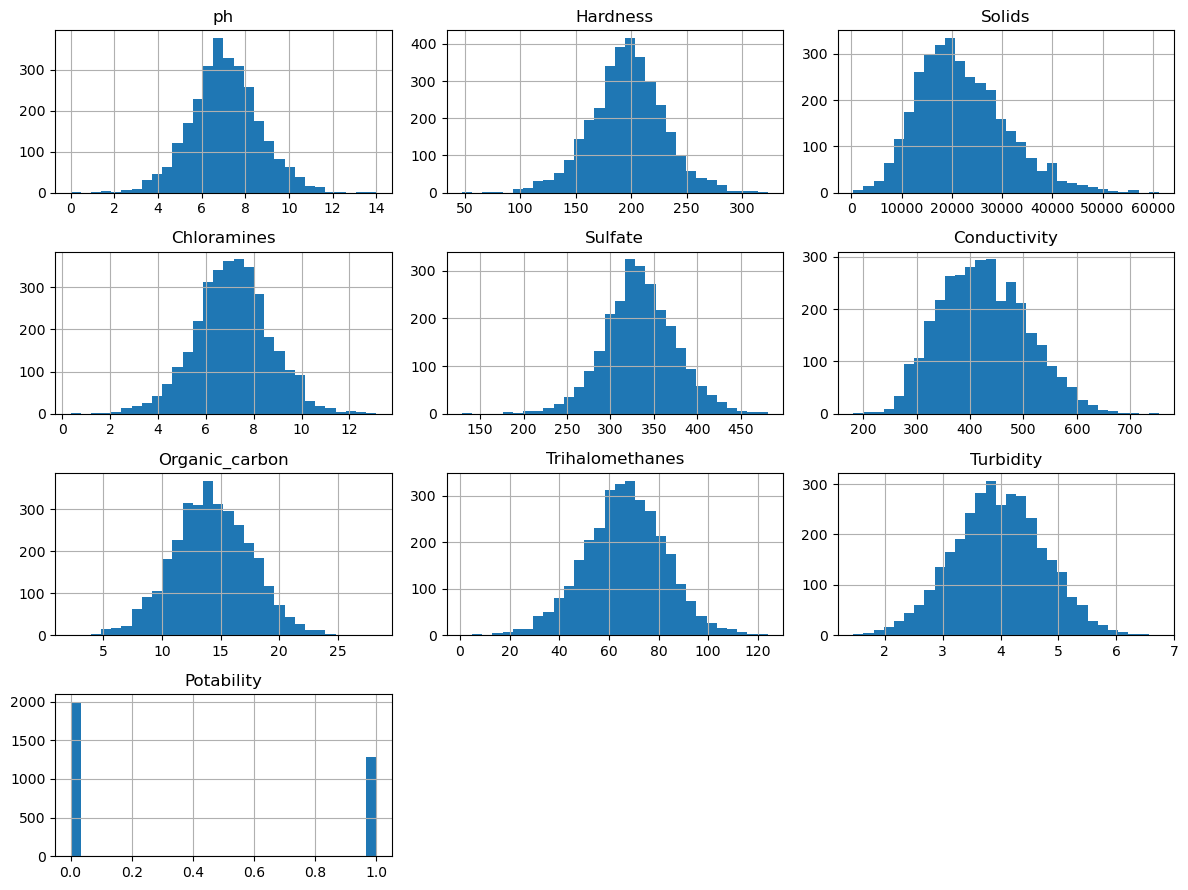

In [6]:
model.mostrar().hist(figsize=(12, 9), bins=30)
plt.tight_layout()
guardar("histogramas.png")
plt.show()

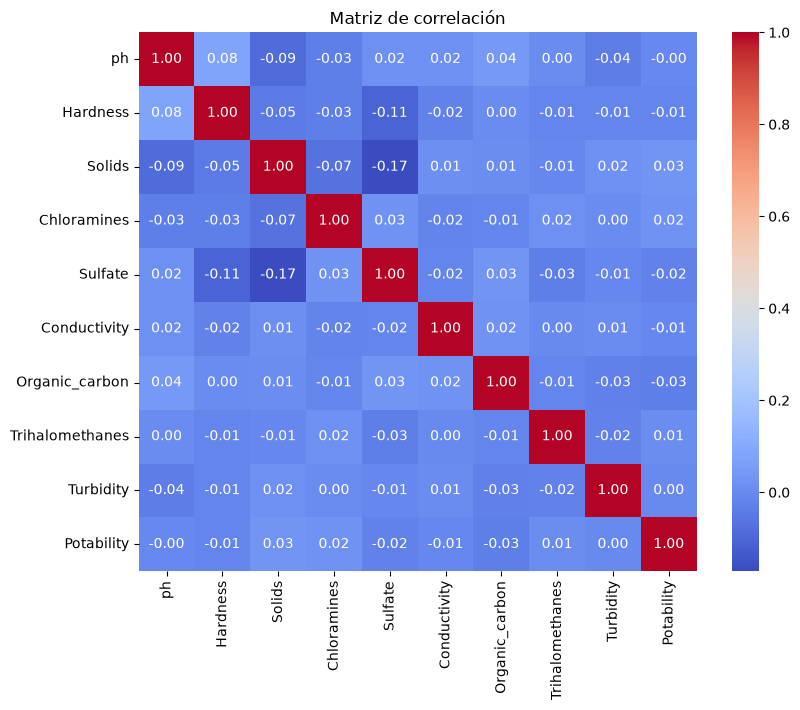

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(model.correlacion(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
guardar("mapa_calor.png")
plt.show()

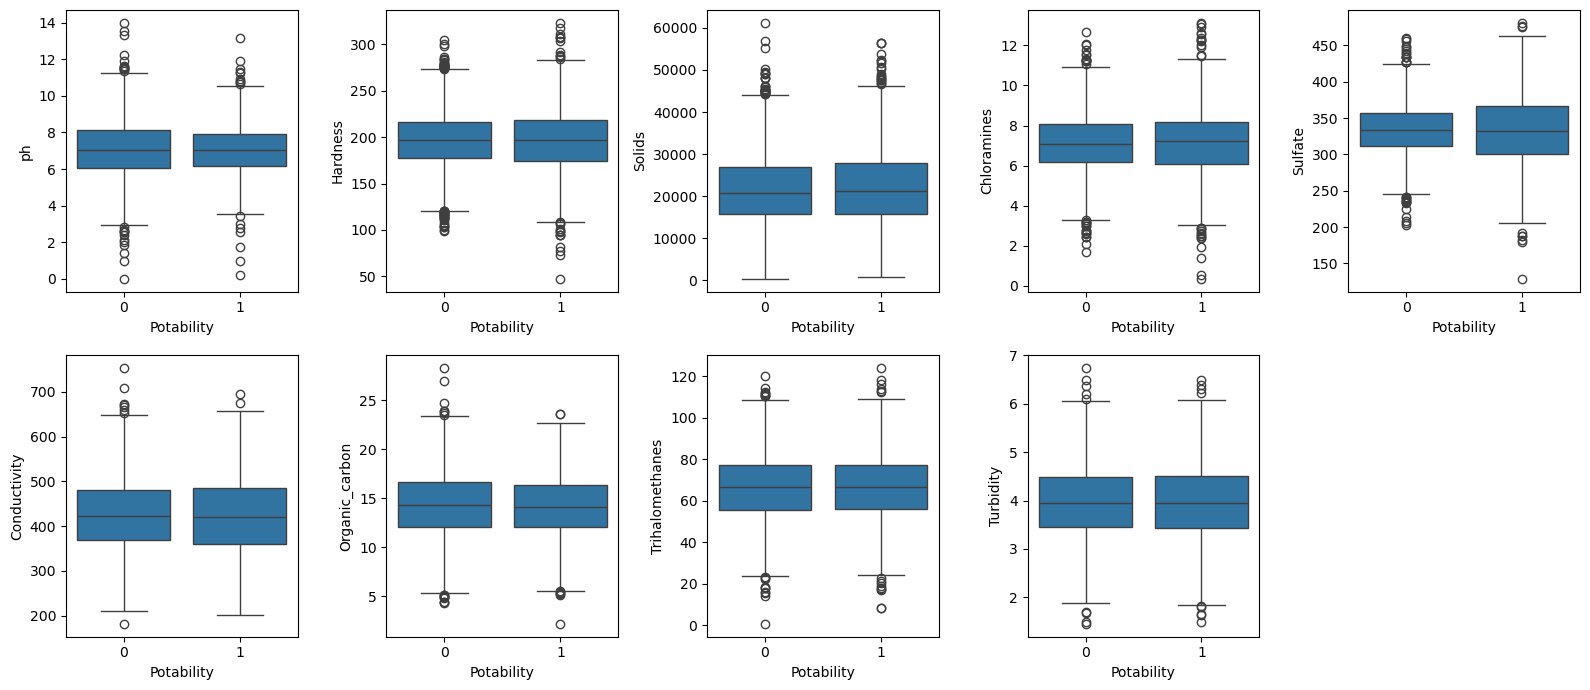

In [8]:
# Distribución de cada variable numérica según la clase
numericas = [col for col in model.correlacion().columns if col != "Potability"]
fig, ax = plt.subplots(2, (len(numericas) + 1) // 2, figsize=(16, 7))
for eje, col in zip(ax.flat, numericas):
    sns.boxplot(data=model.mostrar(), x="Potability", y=col, ax=eje)
for eje in ax.flat[len(numericas):]:
    eje.set_visible(False)
plt.tight_layout()
guardar("boxplots_clase.png")
plt.show()

## Partición entrenamiento / prueba

75 % entrenamiento y 25 % prueba, estratificada por la clase y con semilla 42 para que los experimentos sean reproducibles.

In [9]:
controller.ejecutar("Particionar", test_size=0.25)
y_train = model.df.y_train
ratio = (y_train == 0).sum() / (y_train == 1).sum()   # negativos por cada positivo (para scale_pos_weight)
print("Relación negativos/positivos:", round(ratio, 2))
mejores = {}   # mejor modelo de cada algoritmo


--- Datos ---


,Conjunto,Filas,Predictoras,% clase 0,% clase 1
0,Entrenamiento,2457,9,61.01,38.99
1,Prueba,819,9,60.93,39.07


Relación negativos/positivos: 1.56


## KNN (K vecinos más cercanos)

Se escala con `StandardScaler` por defecto porque KNN trabaja con distancias.

In [10]:
controller.ejecutar("Comparar", algoritmo="knn", configuraciones=[
    {},                                                  # estándar: k=5, uniforme, euclídea
    {"n_neighbors": 15},
    {"n_neighbors": 25},
    {"n_neighbors": 25, "weights": "distance"},
    {"n_neighbors": 25, "p": 1},                         # distancia Manhattan
    {"n_neighbors": 25, "imputacion": "mean"},
    {"n_neighbors": 25, "escalar": False},               # para ver el efecto de no escalar
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
KNN (estándar),0.6093,0.3907,0.7836,0.3375,0.5000,0.3375,0.4030,0.5563,0.6037
KNN (n_neighbors=15),0.6410,0.3590,0.8918,0.2500,0.5970,0.2500,0.3524,0.5521,0.6258
KNN (n_neighbors=25),0.6484,0.3516,0.9299,0.2094,0.6569,0.2094,0.3175,0.5403,0.6375
"KNN (n_neighbors=25, weights=distance)",0.6471,0.3529,0.9279,0.2094,0.6505,0.2094,0.3168,0.5395,0.6403
"KNN (n_neighbors=25, p=1)",0.6374,0.3626,0.9218,0.1938,0.6139,0.1938,0.2945,0.5252,0.6278
"KNN (n_neighbors=25, imputación mean)",0.6471,0.3529,0.9319,0.2031,0.6566,0.2031,0.3103,0.5366,0.6369
"KNN (n_neighbors=25, sin escalar)",0.6081,0.3919,0.9299,0.1062,0.4928,0.1062,0.1748,0.4589,0.5384


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
KNN (estándar),0.6093,0.3907,0.7836,0.3375,0.5000,0.3375,0.4030,0.5563,0.6037
KNN (n_neighbors=15),0.6410,0.3590,0.8918,0.2500,0.5970,0.2500,0.3524,0.5521,0.6258
KNN (n_neighbors=25),0.6484,0.3516,0.9299,0.2094,0.6569,0.2094,0.3175,0.5403,0.6375
"KNN (n_neighbors=25, weights=distance)",0.6471,0.3529,0.9279,0.2094,0.6505,0.2094,0.3168,0.5395,0.6403
"KNN (n_neighbors=25, p=1)",0.6374,0.3626,0.9218,0.1938,0.6139,0.1938,0.2945,0.5252,0.6278
"KNN (n_neighbors=25, imputación mean)",0.6471,0.3529,0.9319,0.2031,0.6566,0.2031,0.3103,0.5366,0.6369
"KNN (n_neighbors=25, sin escalar)",0.6081,0.3919,0.9299,0.1062,0.4928,0.1062,0.1748,0.4589,0.5384



=== Índices de calidad ===


,k,Precisión Global,F1,AUC
0,1,0.5934,0.4384,0.5598
1,6,0.6178,0.2935,0.6064
2,11,0.6178,0.3355,0.6150
3,16,0.6422,0.3040,0.6256
4,21,0.6398,0.3187,0.6309
5,26,0.6484,0.2577,0.6336
6,31,0.6386,0.2673,0.6308
7,36,0.6386,0.2251,0.6309
8,41,0.6496,0.2697,0.6239
9,46,0.6484,0.2340,0.6321


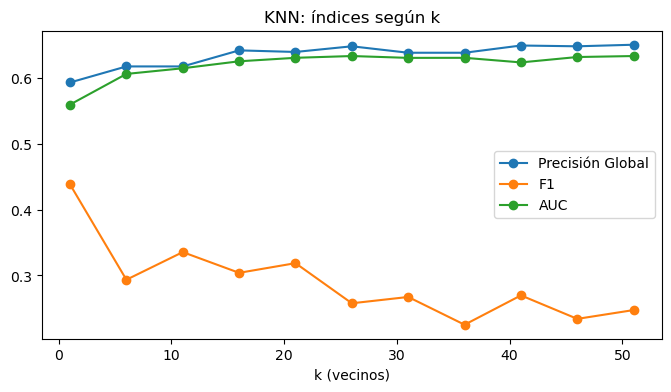

In [11]:
# Índices según la cantidad de vecinos
controller.ejecutar("Curva K", valores_k=range(1, 52, 5))
guardar("knn_curva_k.png")
plt.show()

In [12]:
# Selección de atributos (SelectKBest con ANOVA F): solo las 5 variables más relacionadas con la clase
controller.ejecutar("KNN", n_neighbors=25, n_atributos=5)


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
"KNN (n_neighbors=25, 5 atributos)",0.6239,0.3761,0.8978,0.1969,0.5526,0.1969,0.2903,0.5173,0.5901


Precisión Global     0.6239
Error Global         0.3761
Precisión clase 0    0.8978
Precisión clase 1    0.1969
Precision (VPP)      0.5526
Recall               0.1969
F1                   0.2903
F1 macro             0.5173
AUC                  0.5901
Name: KNN (n_neighbors=25, 5 atributos), dtype: float64


[INFO]: Mejor modelo según F1 macro: KNN (estándar)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
0,KNN (estándar),KNN,0.6093,0.3907,0.7836,0.3375,0.5000,0.3375,0.4030,0.5563,0.6037



--- Datos ---


,Pred 0,Pred 1
Real 0,391,108
Real 1,212,108


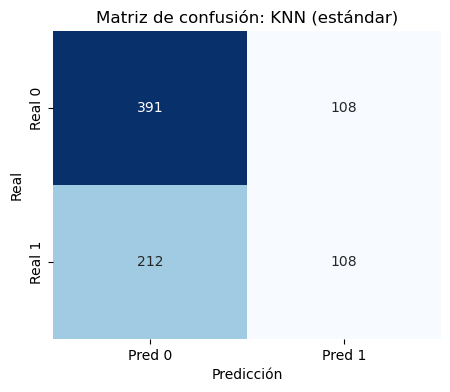


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.6362,0.4526,0.5901,0.6052
Fold 2,0.6341,0.4410,0.5845,0.6305
Fold 3,0.6517,0.4771,0.6080,0.6772
Fold 4,0.6110,0.4399,0.5710,0.6138
Fold 5,0.6395,0.4653,0.5967,0.6327
Promedio,0.6345,0.4552,0.5901,0.6319
Desv. estándar,0.0148,0.0160,0.0138,0.0278


In [13]:
mejores["KNN"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="KNN")
controller.ejecutar("Matriz confusión", nombre=mejores["KNN"])
guardar("knn_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["KNN"])

## Árboles de Decisión (DT)

In [14]:
controller.ejecutar("Comparar", algoritmo="arbol", configuraciones=[
    {},                                                  # estándar: gini, sin límite de profundidad
    {"max_depth": 5},
    {"max_depth": 8, "min_samples_leaf": 20},
    {"criterion": "entropy", "max_depth": 8, "min_samples_leaf": 20},
    {"max_depth": 8, "min_samples_leaf": 20, "class_weight": "balanced"},
    {"ccp_alpha": 0.002},                                # poda por costo-complejidad
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
DT (estándar),0.5592,0.4408,0.6152,0.4719,0.4402,0.4719,0.4555,0.5426,0.5436
DT (max_depth=5),0.6374,0.3626,0.9479,0.1531,0.6533,0.1531,0.2481,0.5046,0.5685
"DT (max_depth=8, min_samples_leaf=20)",0.6557,0.3443,0.8697,0.3219,0.6131,0.3219,0.4221,0.5885,0.6304
"DT (criterion=entropy, max_depth=8, min_samples_leaf=20)",0.6545,0.3455,0.9058,0.2625,0.6412,0.2625,0.3725,0.5670,0.6344
"DT (max_depth=8, min_samples_leaf=20, class_weight=balanced)",0.5543,0.4457,0.4850,0.6625,0.4520,0.6625,0.5374,0.5537,0.6246
DT (ccp_alpha=0.002),0.6386,0.3614,0.8377,0.3281,0.5645,0.3281,0.4150,0.5768,0.6054


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
DT (estándar),0.5592,0.4408,0.6152,0.4719,0.4402,0.4719,0.4555,0.5426,0.5436
DT (max_depth=5),0.6374,0.3626,0.9479,0.1531,0.6533,0.1531,0.2481,0.5046,0.5685
"DT (max_depth=8, min_samples_leaf=20)",0.6557,0.3443,0.8697,0.3219,0.6131,0.3219,0.4221,0.5885,0.6304
"DT (criterion=entropy, max_depth=8, min_samples_leaf=20)",0.6545,0.3455,0.9058,0.2625,0.6412,0.2625,0.3725,0.5670,0.6344
"DT (max_depth=8, min_samples_leaf=20, class_weight=balanced)",0.5543,0.4457,0.4850,0.6625,0.4520,0.6625,0.5374,0.5537,0.6246
DT (ccp_alpha=0.002),0.6386,0.3614,0.8377,0.3281,0.5645,0.3281,0.4150,0.5768,0.6054



[INFO]: Mejor modelo según F1 macro: DT (max_depth=8, min_samples_leaf=20)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
2,"DT (max_depth=8, min_samples_leaf=20)",DT,0.6557,0.3443,0.8697,0.3219,0.6131,0.3219,0.4221,0.5885,0.6304



--- Datos ---


,Pred 0,Pred 1
Real 0,434,65
Real 1,217,103


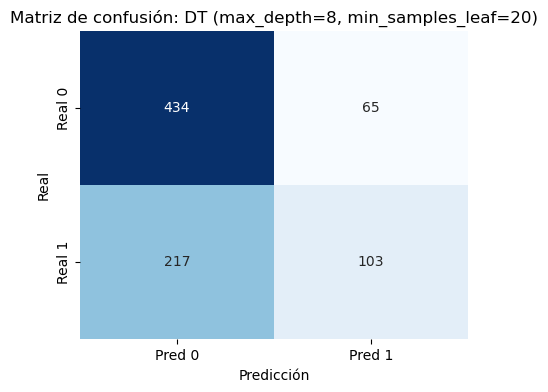


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.6280,0.3579,0.5480,0.5976
Fold 2,0.6484,0.3616,0.5595,0.6486
Fold 3,0.6191,0.3987,0.5600,0.6276
Fold 4,0.6477,0.3162,0.5394,0.5869
Fold 5,0.6314,0.4142,0.5726,0.6298
Promedio,0.6349,0.3697,0.5559,0.6181
Desv. estándar,0.0128,0.0384,0.0127,0.0253


In [15]:
mejores["DT"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="DT")
controller.ejecutar("Matriz confusión", nombre=mejores["DT"])
guardar("dt_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["DT"])

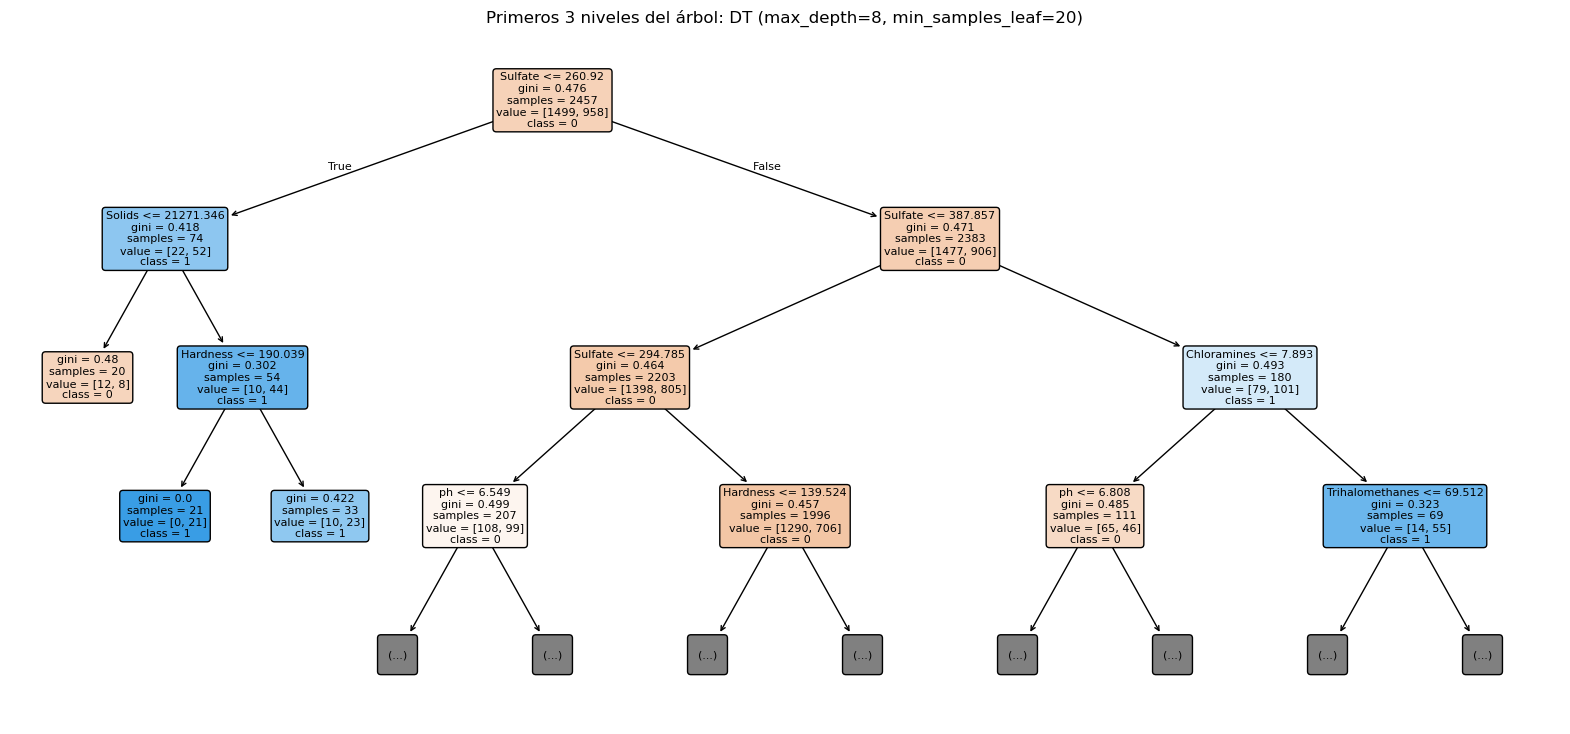

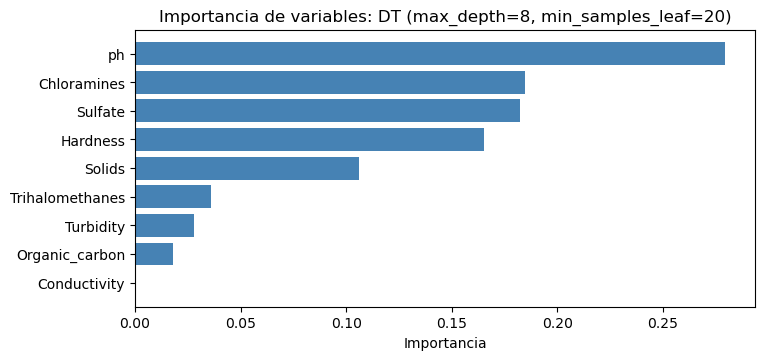

In [16]:
controller.ejecutar("Graficar árbol", nombre=mejores["DT"], profundidad=3)
guardar("dt_arbol.png")
plt.show()
controller.ejecutar("Importancia", nombre=mejores["DT"])
guardar("dt_importancia.png")
plt.show()

## Random Forest (RF)

In [17]:
controller.ejecutar("Comparar", algoritmo="bosque", configuraciones=[
    {},                                                  # estándar: 100 árboles, max_features=sqrt
    {"n_estimators": 500},
    {"n_estimators": 500, "max_features": None},         # bagging puro (todas las variables)
    {"n_estimators": 500, "min_samples_leaf": 3},
    {"n_estimators": 500, "max_depth": 12},
    {"n_estimators": 500, "min_samples_leaf": 5, "class_weight": "balanced_subsample"},
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
RF (estándar),0.6642,0.3358,0.8818,0.3250,0.6380,0.3250,0.4306,0.5963,0.6504
RF (n_estimators=500),0.6740,0.3260,0.9038,0.3156,0.6779,0.3156,0.4307,0.6012,0.6584
"RF (n_estimators=500, max_features=None)",0.6618,0.3382,0.8778,0.3250,0.6303,0.3250,0.4289,0.5943,0.6561
"RF (n_estimators=500, min_samples_leaf=3)",0.6630,0.3370,0.8998,0.2938,0.6528,0.2938,0.4052,0.5850,0.6596
"RF (n_estimators=500, max_depth=12)",0.6606,0.3394,0.9339,0.2344,0.6944,0.2344,0.3505,0.5604,0.6610
"RF (n_estimators=500, min_samples_leaf=5, class_weight=balanced_subsample)",0.6569,0.3431,0.8277,0.3906,0.5924,0.3906,0.4708,0.6085,0.6608


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
RF (estándar),0.6642,0.3358,0.8818,0.3250,0.6380,0.3250,0.4306,0.5963,0.6504
RF (n_estimators=500),0.6740,0.3260,0.9038,0.3156,0.6779,0.3156,0.4307,0.6012,0.6584
"RF (n_estimators=500, max_features=None)",0.6618,0.3382,0.8778,0.3250,0.6303,0.3250,0.4289,0.5943,0.6561
"RF (n_estimators=500, min_samples_leaf=3)",0.6630,0.3370,0.8998,0.2938,0.6528,0.2938,0.4052,0.5850,0.6596
"RF (n_estimators=500, max_depth=12)",0.6606,0.3394,0.9339,0.2344,0.6944,0.2344,0.3505,0.5604,0.6610
"RF (n_estimators=500, min_samples_leaf=5, class_weight=balanced_subsample)",0.6569,0.3431,0.8277,0.3906,0.5924,0.3906,0.4708,0.6085,0.6608


In [18]:
# Selección de atributos sobre el bosque estándar
controller.ejecutar("Random Forest", n_atributos=5)


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
RF (5 atributos),0.6105,0.3895,0.8317,0.2656,0.5030,0.2656,0.3476,0.5350,0.5870


Precisión Global     0.6105
Error Global         0.3895
Precisión clase 0    0.8317
Precisión clase 1    0.2656
Precision (VPP)      0.5030
Recall               0.2656
F1                   0.3476
F1 macro             0.5350
AUC                  0.5870
Name: RF (5 atributos), dtype: float64


[INFO]: Mejor modelo según F1 macro: RF (n_estimators=500, min_samples_leaf=5, class_weight=balanced_subsample)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
5,"RF (n_estimators=500, min_samples_leaf=5, class_weight=balanced_subsample)",RF,0.6569,0.3431,0.8277,0.3906,0.5924,0.3906,0.4708,0.6085,0.6608



--- Datos ---


,Pred 0,Pred 1
Real 0,413,86
Real 1,195,125


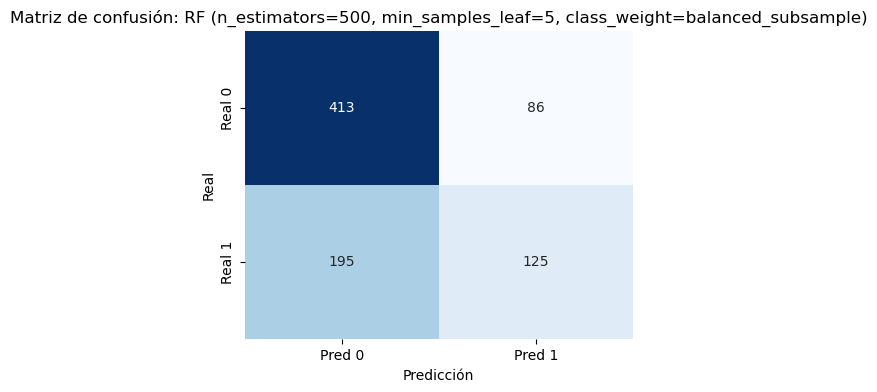


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.6545,0.4970,0.6169,0.6335
Fold 2,0.6585,0.4717,0.6097,0.6601
Fold 3,0.6843,0.5171,0.6413,0.7093
Fold 4,0.6843,0.5141,0.6402,0.7083
Fold 5,0.6273,0.4696,0.5911,0.6696
Promedio,0.6618,0.4939,0.6199,0.6762
Desv. estándar,0.0238,0.0226,0.0213,0.0326


In [19]:
mejores["RF"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="RF")
controller.ejecutar("Matriz confusión", nombre=mejores["RF"])
guardar("rf_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["RF"])

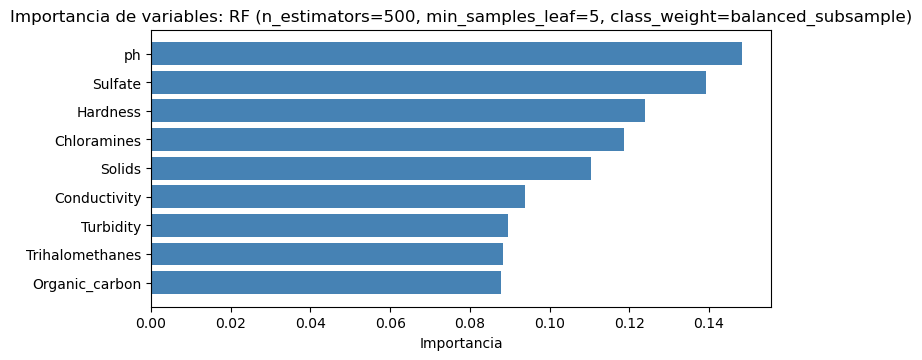

In [20]:
controller.ejecutar("Importancia", nombre=mejores["RF"])
guardar("rf_importancia.png")
plt.show()

## XGBoost

In [21]:
controller.ejecutar("Comparar", algoritmo="xgboost", configuraciones=[
    {},                                                  # estándar: 100 árboles, lr=0.3, profundidad 6
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 6, "subsample": 0.8, "colsample_bytree": 0.8},
    {"n_estimators": 500, "learning_rate": 0.01, "max_depth": 6, "subsample": 0.8, "colsample_bytree": 0.8},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 6, "subsample": 0.8, "colsample_bytree": 0.8,
     "scale_pos_weight": round(ratio, 2)},               # peso extra a la clase minoritaria
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
XGBoost (estándar),0.6252,0.3748,0.7856,0.3750,0.5286,0.3750,0.4388,0.5787,0.6194
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4)",0.6557,0.3443,0.8677,0.3250,0.6118,0.3250,0.4245,0.5894,0.6294
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8)",0.6459,0.3541,0.8357,0.3500,0.5773,0.3500,0.4358,0.5889,0.6382
"XGBoost (n_estimators=500, learning_rate=0.01, max_depth=6, subsample=0.8, colsample_bytree=0.8)",0.6642,0.3358,0.9058,0.2875,0.6619,0.2875,0.4009,0.5838,0.6527
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.56)",0.6288,0.3712,0.7435,0.4500,0.5294,0.4500,0.4865,0.5979,0.6388


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
XGBoost (estándar),0.6252,0.3748,0.7856,0.3750,0.5286,0.3750,0.4388,0.5787,0.6194
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4)",0.6557,0.3443,0.8677,0.3250,0.6118,0.3250,0.4245,0.5894,0.6294
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8)",0.6459,0.3541,0.8357,0.3500,0.5773,0.3500,0.4358,0.5889,0.6382
"XGBoost (n_estimators=500, learning_rate=0.01, max_depth=6, subsample=0.8, colsample_bytree=0.8)",0.6642,0.3358,0.9058,0.2875,0.6619,0.2875,0.4009,0.5838,0.6527
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.56)",0.6288,0.3712,0.7435,0.4500,0.5294,0.4500,0.4865,0.5979,0.6388



[INFO]: Mejor modelo según F1 macro: XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.56)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
4,"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.56)",XGBoost,0.6288,0.3712,0.7435,0.4500,0.5294,0.4500,0.4865,0.5979,0.6388



--- Datos ---


,Pred 0,Pred 1
Real 0,371,128
Real 1,176,144


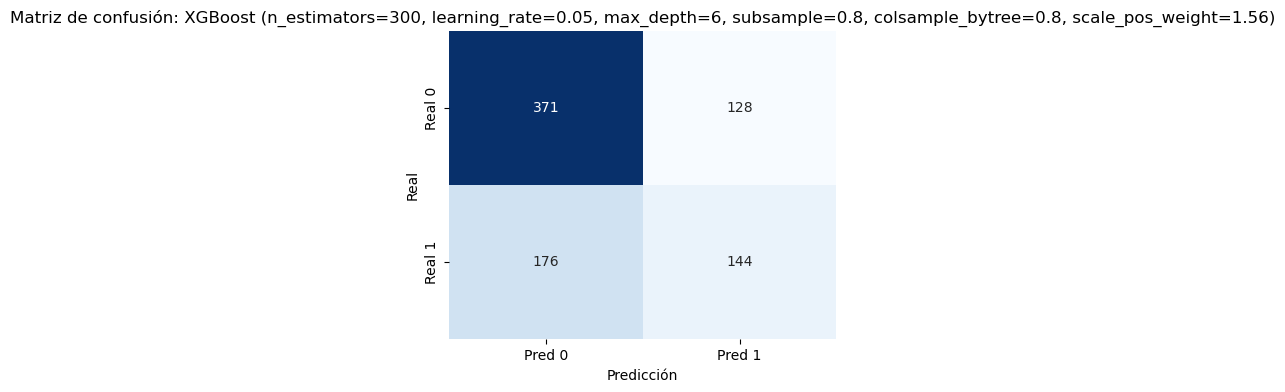


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.6179,0.4863,0.5911,0.6248
Fold 2,0.5996,0.4513,0.5680,0.6448
Fold 3,0.6538,0.5029,0.6186,0.6842
Fold 4,0.6680,0.5510,0.6438,0.6943
Fold 5,0.6354,0.5375,0.6183,0.6872
Promedio,0.6349,0.5058,0.6080,0.6671
Desv. estándar,0.0273,0.0400,0.0291,0.0305


In [22]:
mejores["XGBoost"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="XGBoost")
controller.ejecutar("Matriz confusión", nombre=mejores["XGBoost"])
guardar("xgboost_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["XGBoost"])

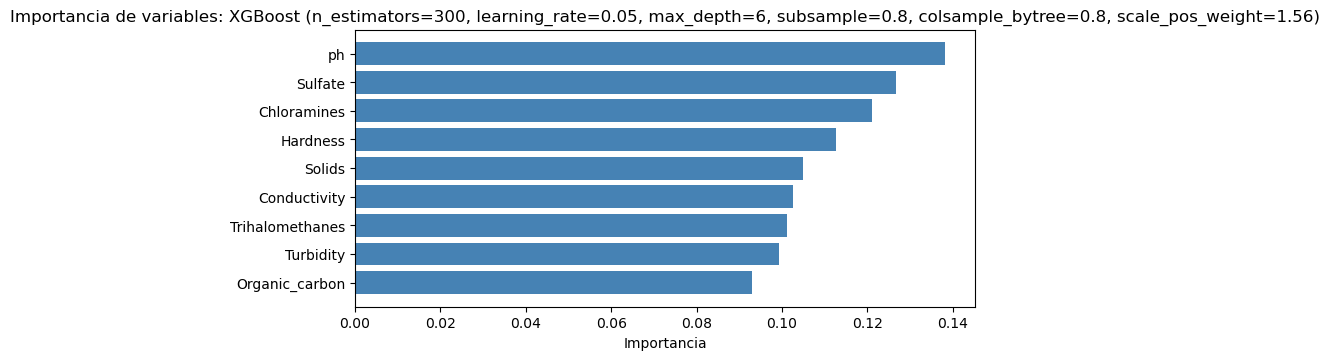

In [23]:
controller.ejecutar("Importancia", nombre=mejores["XGBoost"])
guardar("xgboost_importancia.png")
plt.show()

## AdaBoost

In [24]:
controller.ejecutar("Comparar", algoritmo="adaboost", configuraciones=[
    {},                                                  # estándar: 50 stumps, lr=1
    {"n_estimators": 200},
    {"n_estimators": 200, "learning_rate": 0.5, "profundidad_base": 2},
    {"n_estimators": 300, "learning_rate": 0.1, "profundidad_base": 3},
    {"n_estimators": 200, "learning_rate": 0.05, "profundidad_base": 4},
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
AdaBoost (estándar),0.6178,0.3822,0.9599,0.0844,0.5745,0.0844,0.1471,0.4504,0.5790
AdaBoost (n_estimators=200),0.6203,0.3797,0.9559,0.0969,0.5849,0.0969,0.1662,0.4602,0.5805
"AdaBoost (n_estimators=200, learning_rate=0.5, profundidad_base=2)",0.6105,0.3895,0.9198,0.1281,0.5062,0.1281,0.2045,0.4733,0.5820
"AdaBoost (n_estimators=300, learning_rate=0.1, profundidad_base=3)",0.6288,0.3712,0.9559,0.1187,0.6333,0.1187,0.2000,0.4792,0.6158
"AdaBoost (n_estimators=200, learning_rate=0.05, profundidad_base=4)",0.6471,0.3529,0.9639,0.1531,0.7313,0.1531,0.2532,0.5111,0.6264


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
AdaBoost (estándar),0.6178,0.3822,0.9599,0.0844,0.5745,0.0844,0.1471,0.4504,0.5790
AdaBoost (n_estimators=200),0.6203,0.3797,0.9559,0.0969,0.5849,0.0969,0.1662,0.4602,0.5805
"AdaBoost (n_estimators=200, learning_rate=0.5, profundidad_base=2)",0.6105,0.3895,0.9198,0.1281,0.5062,0.1281,0.2045,0.4733,0.5820
"AdaBoost (n_estimators=300, learning_rate=0.1, profundidad_base=3)",0.6288,0.3712,0.9559,0.1187,0.6333,0.1187,0.2000,0.4792,0.6158
"AdaBoost (n_estimators=200, learning_rate=0.05, profundidad_base=4)",0.6471,0.3529,0.9639,0.1531,0.7313,0.1531,0.2532,0.5111,0.6264



[INFO]: Mejor modelo según F1 macro: AdaBoost (n_estimators=200, learning_rate=0.05, profundidad_base=4)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
4,"AdaBoost (n_estimators=200, learning_rate=0.05, profundidad_base=4)",AdaBoost,0.6471,0.3529,0.9639,0.1531,0.7313,0.1531,0.2532,0.5111,0.6264



--- Datos ---


,Pred 0,Pred 1
Real 0,481,18
Real 1,271,49


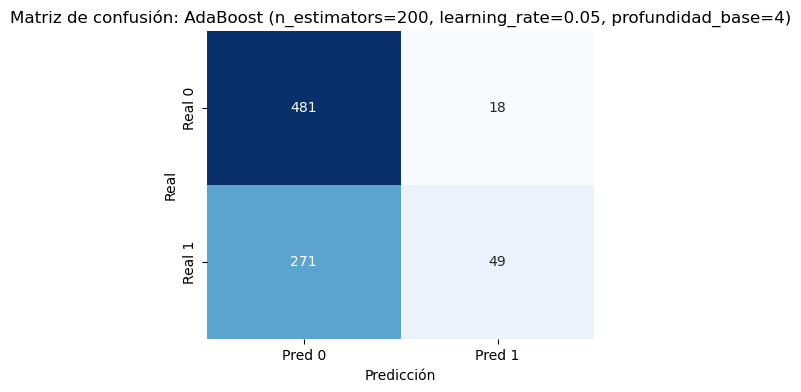


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.6382,0.2393,0.5010,0.6077
Fold 2,0.6382,0.2393,0.5010,0.6128
Fold 3,0.6762,0.3614,0.5723,0.6464
Fold 4,0.6619,0.2783,0.5288,0.6512
Fold 5,0.6171,0.2101,0.4787,0.5600
Promedio,0.6463,0.2657,0.5163,0.6156
Desv. estándar,0.0230,0.0588,0.0360,0.0367


In [25]:
mejores["AdaBoost"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="AdaBoost")
controller.ejecutar("Matriz confusión", nombre=mejores["AdaBoost"])
guardar("adaboost_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["AdaBoost"])

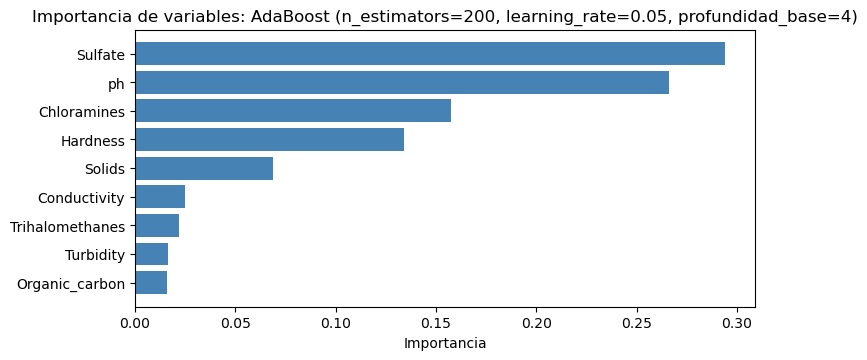

In [26]:
controller.ejecutar("Importancia", nombre=mejores["AdaBoost"])
guardar("adaboost_importancia.png")
plt.show()

## Comparación de los mejores modelos

In [27]:
controller.ejecutar("Resultados")


=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
0,KNN (estándar),KNN,0.6093,0.3907,0.7836,0.3375,0.5000,0.3375,0.4030,0.5563,0.6037
1,KNN (n_neighbors=15),KNN,0.6410,0.3590,0.8918,0.2500,0.5970,0.2500,0.3524,0.5521,0.6258
2,KNN (n_neighbors=25),KNN,0.6484,0.3516,0.9299,0.2094,0.6569,0.2094,0.3175,0.5403,0.6375
3,"KNN (n_neighbors=25, weights=distance)",KNN,0.6471,0.3529,0.9279,0.2094,0.6505,0.2094,0.3168,0.5395,0.6403
4,"KNN (n_neighbors=25, p=1)",KNN,0.6374,0.3626,0.9218,0.1938,0.6139,0.1938,0.2945,0.5252,0.6278
5,"KNN (n_neighbors=25, imputación mean)",KNN,0.6471,0.3529,0.9319,0.2031,0.6566,0.2031,0.3103,0.5366,0.6369
6,"KNN (n_neighbors=25, sin escalar)",KNN,0.6081,0.3919,0.9299,0.1062,0.4928,0.1062,0.1748,0.4589,0.5384
7,"KNN (n_neighbors=25, 5 atributos)",KNN,0.6239,0.3761,0.8978,0.1969,0.5526,0.1969,0.2903,0.5173,0.5901
8,DT (estándar),DT,0.5592,0.4408,0.6152,0.4719,0.4402,0.4719,0.4555,0.5426,0.5436
9,DT (max_depth=5),DT,0.6374,0.3626,0.9479,0.1531,0.6533,0.1531,0.2481,0.5046,0.5685


In [28]:
tabla = model.resultados().set_index("Modelo").loc[list(mejores.values())]
view.mostrar_indices(tabla.sort_values(CRITERIO, ascending=False))


=== Índices de calidad ===


,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
Modelo,,,,,,,,,,
"RF (n_estimators=500, min_samples_leaf=5, class_weight=balanced_subsample)",RF,0.6569,0.3431,0.8277,0.3906,0.5924,0.3906,0.4708,0.6085,0.6608
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.56)",XGBoost,0.6288,0.3712,0.7435,0.4500,0.5294,0.4500,0.4865,0.5979,0.6388
"DT (max_depth=8, min_samples_leaf=20)",DT,0.6557,0.3443,0.8697,0.3219,0.6131,0.3219,0.4221,0.5885,0.6304
KNN (estándar),KNN,0.6093,0.3907,0.7836,0.3375,0.5000,0.3375,0.4030,0.5563,0.6037
"AdaBoost (n_estimators=200, learning_rate=0.05, profundidad_base=4)",AdaBoost,0.6471,0.3529,0.9639,0.1531,0.7313,0.1531,0.2532,0.5111,0.6264


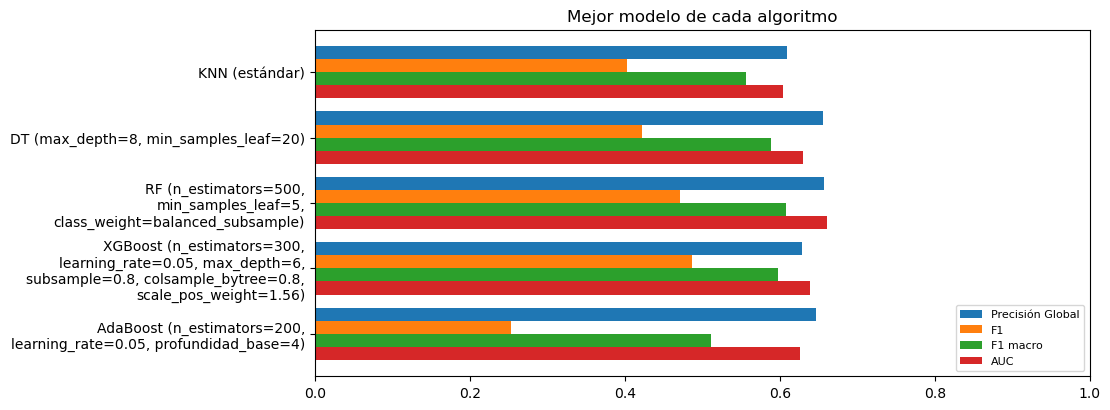

In [29]:
controller.ejecutar("Gráfico comparación", nombres=list(mejores.values()),
                    titulo="Mejor modelo de cada algoritmo")
guardar("comparacion_mejores.png")
plt.show()

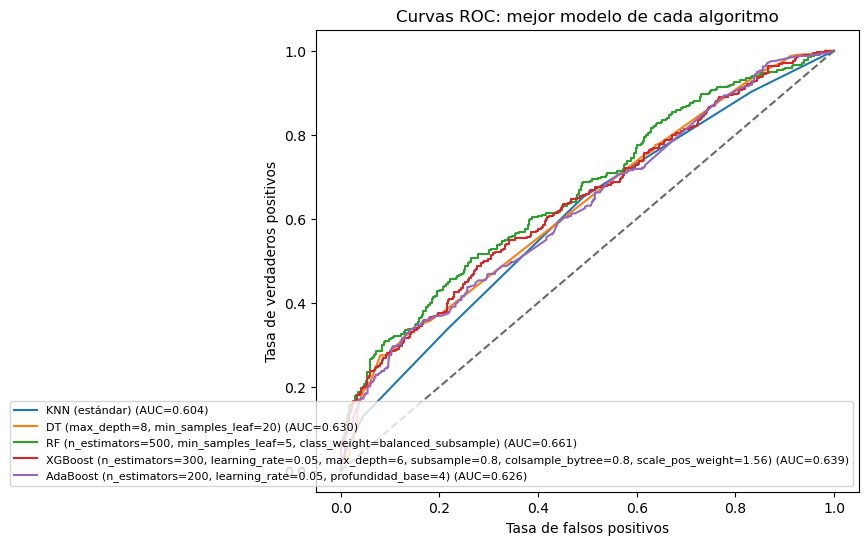

In [30]:
controller.ejecutar("ROC", nombres=list(mejores.values()), titulo="Curvas ROC: mejor modelo de cada algoritmo")
guardar("roc_mejores.png")
plt.show()

In [31]:
# Se guardan los índices de todos los experimentos
model.resultados().to_csv(f"{CARPETA}/resultados.csv", index=False)

# 2. Predicción de diabetes (diabetes_prediction_dataset)

100 000 pacientes, 8 predictoras (2 categóricas: `gender` y `smoking_history`) y la variable a predecir `diabetes` (1 = diabético). No tiene nulos, pero sí filas duplicadas (se eliminan al particionar) y un fuerte desbalance de clases (~8.5 % de positivos), por lo que la precisión global no basta para comparar modelos. Las categóricas se codifican con one-hot dentro del pipeline.

In [32]:
CARPETA = "figuras/diabetes"
os.makedirs(CARPETA, exist_ok=True)

# --- Inicialización MVC ---
# con variable_predecir el modelo usa Clasificacion (Clasificacion -> Supervisado -> EDA)
model = DataFrameModel("datos/diabetes_prediction_dataset.csv", variable_predecir="diabetes")
view = DataFrameView()
controller = DataFrameController(model, view)

# --- Exploración inicial ---
controller.iniciar()


[INFO]: Iniciando controlador...

[INFO]: --- Primeras filas del dataset ---

--- Datos ---


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.00,0,1,never,25.19,6.60,140,0
1,Female,54.00,0,0,No Info,27.32,6.60,80,0
2,Male,28.00,0,0,never,27.32,5.70,158,0
3,Female,36.00,0,0,current,23.45,5.00,155,0
4,Male,76.00,1,1,current,20.14,4.80,155,0
5,Female,20.00,0,0,never,27.32,6.60,85,0
6,Female,44.00,0,0,never,19.31,6.50,200,1
7,Female,79.00,0,0,No Info,23.86,5.70,85,0
8,Male,42.00,0,0,never,33.64,4.80,145,0
9,Female,32.00,0,0,never,27.32,5.00,100,0



[INFO]: Dimensiones del dataset: (100000, 9)


## Análisis exploratorio

In [33]:
view.mostrar(model.tipos_datos())
view.mostrar(model.contar_nulos())
print("Filas duplicadas:", len(model.detectar_duplicados()))


--- Datos ---


,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64



--- Datos ---


,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Filas duplicadas: 3854


In [34]:
controller.ejecutar("Distribución clases")


--- Datos ---


,cantidad,porcentaje
diabetes,,
0,91500,91.50
1,8500,8.50


In [35]:
controller.ejecutar("Estadísticas")


=== Estadísticas descriptivas ===


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,41.89,0.07,0.04,27.32,5.53,138.06,0.09
std,22.52,0.26,0.19,6.64,1.07,40.71,0.28
min,0.08,0.00,0.00,10.01,3.50,80.00,0.00
25%,24.00,0.00,0.00,23.63,4.80,100.00,0.00
50%,43.00,0.00,0.00,27.32,5.80,140.00,0.00
75%,60.00,0.00,0.00,29.58,6.20,159.00,0.00
max,80.00,1.00,1.00,95.69,9.00,300.00,1.00


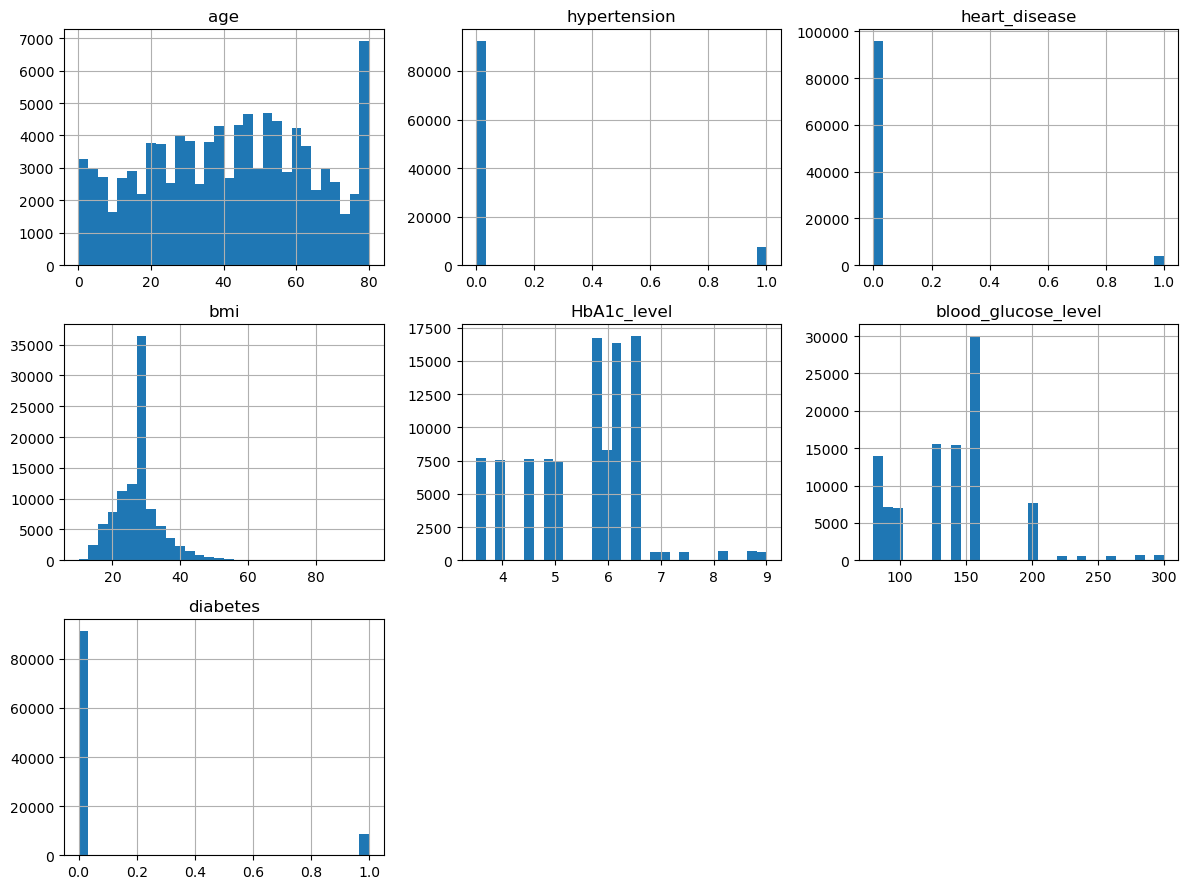

In [36]:
model.mostrar().hist(figsize=(12, 9), bins=30)
plt.tight_layout()
guardar("histogramas.png")
plt.show()

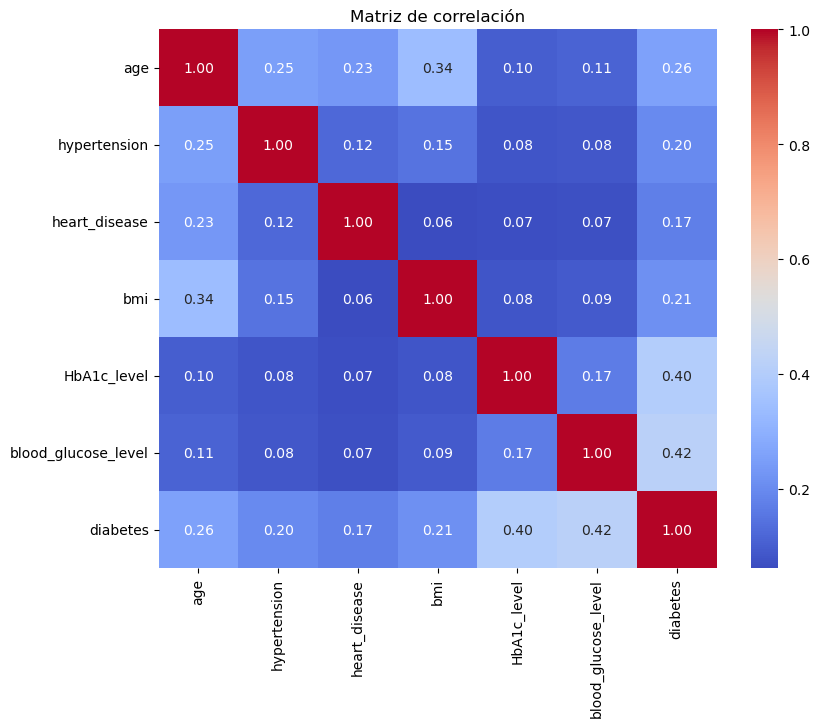

In [37]:
plt.figure(figsize=(9, 7))
sns.heatmap(model.correlacion(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
guardar("mapa_calor.png")
plt.show()

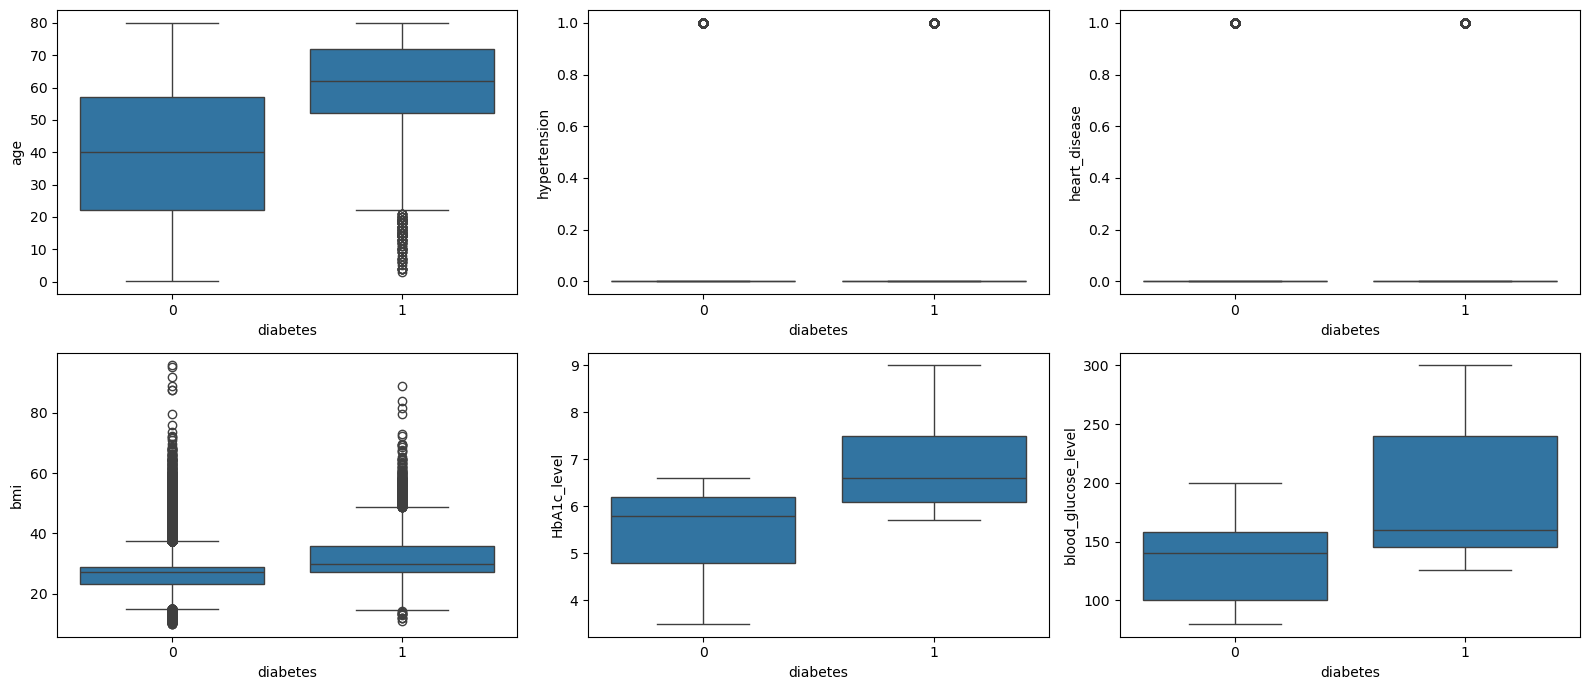

In [38]:
# Distribución de cada variable numérica según la clase
numericas = [col for col in model.correlacion().columns if col != "diabetes"]
fig, ax = plt.subplots(2, (len(numericas) + 1) // 2, figsize=(16, 7))
for eje, col in zip(ax.flat, numericas):
    sns.boxplot(data=model.mostrar(), x="diabetes", y=col, ax=eje)
for eje in ax.flat[len(numericas):]:
    eje.set_visible(False)
plt.tight_layout()
guardar("boxplots_clase.png")
plt.show()

In [39]:
# Porcentaje de diabéticos según cada variable categórica
for col in ['gender', 'smoking_history']:
    tabla = pd.crosstab(model.obtener_columna(col), model.obtener_columna("diabetes"), normalize="index") * 100
    view.mostrar(tabla.round(2))


--- Datos ---


diabetes,0,1
gender,,
Female,92.38,7.62
Male,90.25,9.75
Other,100.00,0.00



--- Datos ---


diabetes,0,1
smoking_history,,
No Info,95.94,4.06
current,89.79,10.21
ever,88.21,11.79
former,83.00,17.00
never,90.47,9.53
not current,89.30,10.70


## Partición entrenamiento / prueba

75 % entrenamiento y 25 % prueba, estratificada por la clase y con semilla 42 para que los experimentos sean reproducibles.

In [40]:
controller.ejecutar("Particionar", test_size=0.25)
y_train = model.df.y_train
ratio = (y_train == 0).sum() / (y_train == 1).sum()   # negativos por cada positivo (para scale_pos_weight)
print("Relación negativos/positivos:", round(ratio, 2))
mejores = {}   # mejor modelo de cada algoritmo


--- Datos ---


,Conjunto,Filas,Predictoras,% clase 0,% clase 1
0,Entrenamiento,72109,8,91.18,8.82
1,Prueba,24037,8,91.18,8.82


Relación negativos/positivos: 10.34


## KNN (K vecinos más cercanos)

Se escala con `StandardScaler` por defecto porque KNN trabaja con distancias.

In [41]:
controller.ejecutar("Comparar", algoritmo="knn", configuraciones=[
    {},                                                  # estándar: k=5, uniforme, euclídea
    {"n_neighbors": 11},
    {"n_neighbors": 25},
    {"n_neighbors": 11, "weights": "distance"},
    {"n_neighbors": 11, "p": 1},                         # distancia Manhattan
    {"n_neighbors": 11, "escalar": False},               # para ver el efecto de no escalar
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
KNN (estándar),0.9589,0.0411,0.9925,0.6124,0.8873,0.6124,0.7247,0.8513,0.9022
KNN (n_neighbors=11),0.9599,0.0401,0.9963,0.5837,0.9393,0.5837,0.7200,0.8492,0.9325
KNN (n_neighbors=25),0.9596,0.0404,0.9984,0.5587,0.9713,0.5587,0.7094,0.8438,0.9512
"KNN (n_neighbors=11, weights=distance)",0.9599,0.0401,0.9948,0.5997,0.9171,0.5997,0.7252,0.8518,0.9306
"KNN (n_neighbors=11, p=1)",0.9599,0.0401,0.9973,0.5743,0.9531,0.5743,0.7167,0.8476,0.9326
"KNN (n_neighbors=11, sin escalar)",0.9533,0.0467,0.9974,0.4974,0.9487,0.4974,0.6526,0.8138,0.9146


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
KNN (estándar),0.9589,0.0411,0.9925,0.6124,0.8873,0.6124,0.7247,0.8513,0.9022
KNN (n_neighbors=11),0.9599,0.0401,0.9963,0.5837,0.9393,0.5837,0.7200,0.8492,0.9325
KNN (n_neighbors=25),0.9596,0.0404,0.9984,0.5587,0.9713,0.5587,0.7094,0.8438,0.9512
"KNN (n_neighbors=11, weights=distance)",0.9599,0.0401,0.9948,0.5997,0.9171,0.5997,0.7252,0.8518,0.9306
"KNN (n_neighbors=11, p=1)",0.9599,0.0401,0.9973,0.5743,0.9531,0.5743,0.7167,0.8476,0.9326
"KNN (n_neighbors=11, sin escalar)",0.9533,0.0467,0.9974,0.4974,0.9487,0.4974,0.6526,0.8138,0.9146



=== Índices de calidad ===


,k,Precisión Global,F1,AUC
0,1,0.9465,0.6889,0.8224
1,6,0.9596,0.7139,0.9105
2,11,0.9599,0.7200,0.9325
3,16,0.9597,0.7101,0.9440
4,21,0.9601,0.7146,0.9487
5,26,0.9591,0.7039,0.9517
6,31,0.9593,0.7067,0.9540
7,36,0.9586,0.6980,0.9557
8,41,0.9585,0.6976,0.9572
9,46,0.9583,0.6947,0.9573


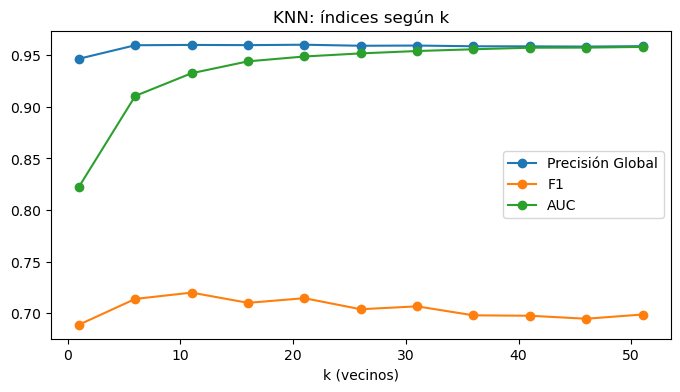

In [42]:
# Índices según la cantidad de vecinos
controller.ejecutar("Curva K", valores_k=range(1, 52, 5))
guardar("knn_curva_k.png")
plt.show()

In [43]:
# Selección de atributos (SelectKBest con ANOVA F): solo las 6 variables más relacionadas con la clase
controller.ejecutar("KNN", n_neighbors=11, n_atributos=6)


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
"KNN (n_neighbors=11, 6 atributos)",0.9647,0.0353,0.9963,0.6384,0.9436,0.6384,0.7615,0.8712,0.9343


Precisión Global     0.9647
Error Global         0.0353
Precisión clase 0    0.9963
Precisión clase 1    0.6384
Precision (VPP)      0.9436
Recall               0.6384
F1                   0.7615
F1 macro             0.8712
AUC                  0.9343
Name: KNN (n_neighbors=11, 6 atributos), dtype: float64


[INFO]: Mejor modelo según F1 macro: KNN (n_neighbors=11, 6 atributos)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
6,"KNN (n_neighbors=11, 6 atributos)",KNN,0.9647,0.0353,0.9963,0.6384,0.9436,0.6384,0.7615,0.8712,0.9343



--- Datos ---


,Pred 0,Pred 1
Real 0,21835,81
Real 1,767,1354


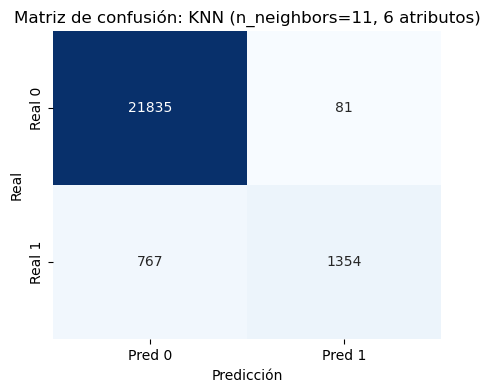


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.9646,0.7594,0.8702,0.9407
Fold 2,0.9644,0.7579,0.8694,0.9341
Fold 3,0.9649,0.7609,0.8710,0.9418
Fold 4,0.9646,0.7567,0.8688,0.9431
Fold 5,0.9653,0.7666,0.8739,0.9420
Promedio,0.9648,0.7603,0.8706,0.9403
Desv. estándar,0.0003,0.0038,0.0020,0.0036


In [44]:
mejores["KNN"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="KNN")
controller.ejecutar("Matriz confusión", nombre=mejores["KNN"])
guardar("knn_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["KNN"])

## Árboles de Decisión (DT)

In [45]:
controller.ejecutar("Comparar", algoritmo="arbol", configuraciones=[
    {},                                                  # estándar: gini, sin límite de profundidad
    {"max_depth": 5},
    {"max_depth": 10},
    {"max_depth": 10, "min_samples_leaf": 20},
    {"criterion": "entropy", "max_depth": 10, "min_samples_leaf": 20},
    {"max_depth": 10, "min_samples_leaf": 20, "class_weight": "balanced"},
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
DT (estándar),0.9477,0.0523,0.9682,0.7360,0.6916,0.7360,0.7131,0.8422,0.8524
DT (max_depth=5),0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9492
DT (max_depth=10),0.9709,0.0291,0.9988,0.6832,0.9817,0.6832,0.8057,0.8950,0.9712
"DT (max_depth=10, min_samples_leaf=20)",0.9713,0.0287,0.9991,0.6836,0.9864,0.6836,0.8076,0.8960,0.9718
"DT (criterion=entropy, max_depth=10, min_samples_leaf=20)",0.9710,0.0290,0.9992,0.6799,0.9883,0.6799,0.8056,0.8950,0.9710
"DT (max_depth=10, min_samples_leaf=20, class_weight=balanced)",0.8828,0.1172,0.8791,0.9208,0.4243,0.9208,0.5809,0.7564,0.9721


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
DT (estándar),0.9477,0.0523,0.9682,0.7360,0.6916,0.7360,0.7131,0.8422,0.8524
DT (max_depth=5),0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9492
DT (max_depth=10),0.9709,0.0291,0.9988,0.6832,0.9817,0.6832,0.8057,0.8950,0.9712
"DT (max_depth=10, min_samples_leaf=20)",0.9713,0.0287,0.9991,0.6836,0.9864,0.6836,0.8076,0.8960,0.9718
"DT (criterion=entropy, max_depth=10, min_samples_leaf=20)",0.9710,0.0290,0.9992,0.6799,0.9883,0.6799,0.8056,0.8950,0.9710
"DT (max_depth=10, min_samples_leaf=20, class_weight=balanced)",0.8828,0.1172,0.8791,0.9208,0.4243,0.9208,0.5809,0.7564,0.9721



[INFO]: Mejor modelo según F1 macro: DT (max_depth=10, min_samples_leaf=20)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
3,"DT (max_depth=10, min_samples_leaf=20)",DT,0.9713,0.0287,0.9991,0.6836,0.9864,0.6836,0.8076,0.8960,0.9718



--- Datos ---


,Pred 0,Pred 1
Real 0,21896,20
Real 1,671,1450


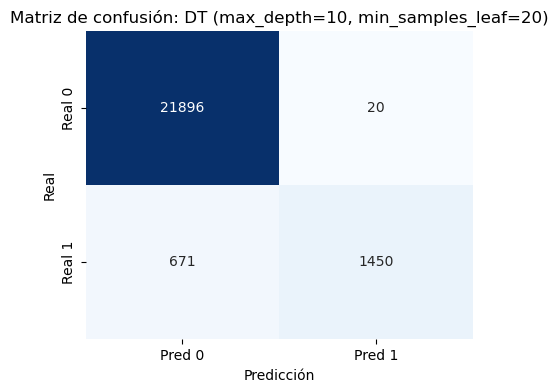


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.9697,0.7970,0.8903,0.9754
Fold 2,0.9696,0.7959,0.8897,0.9720
Fold 3,0.9707,0.8033,0.8938,0.9751
Fold 4,0.9701,0.7989,0.8914,0.9716
Fold 5,0.9716,0.8121,0.8984,0.9769
Promedio,0.9703,0.8015,0.8927,0.9742
Desv. estándar,0.0008,0.0066,0.0035,0.0023


In [46]:
mejores["DT"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="DT")
controller.ejecutar("Matriz confusión", nombre=mejores["DT"])
guardar("dt_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["DT"])

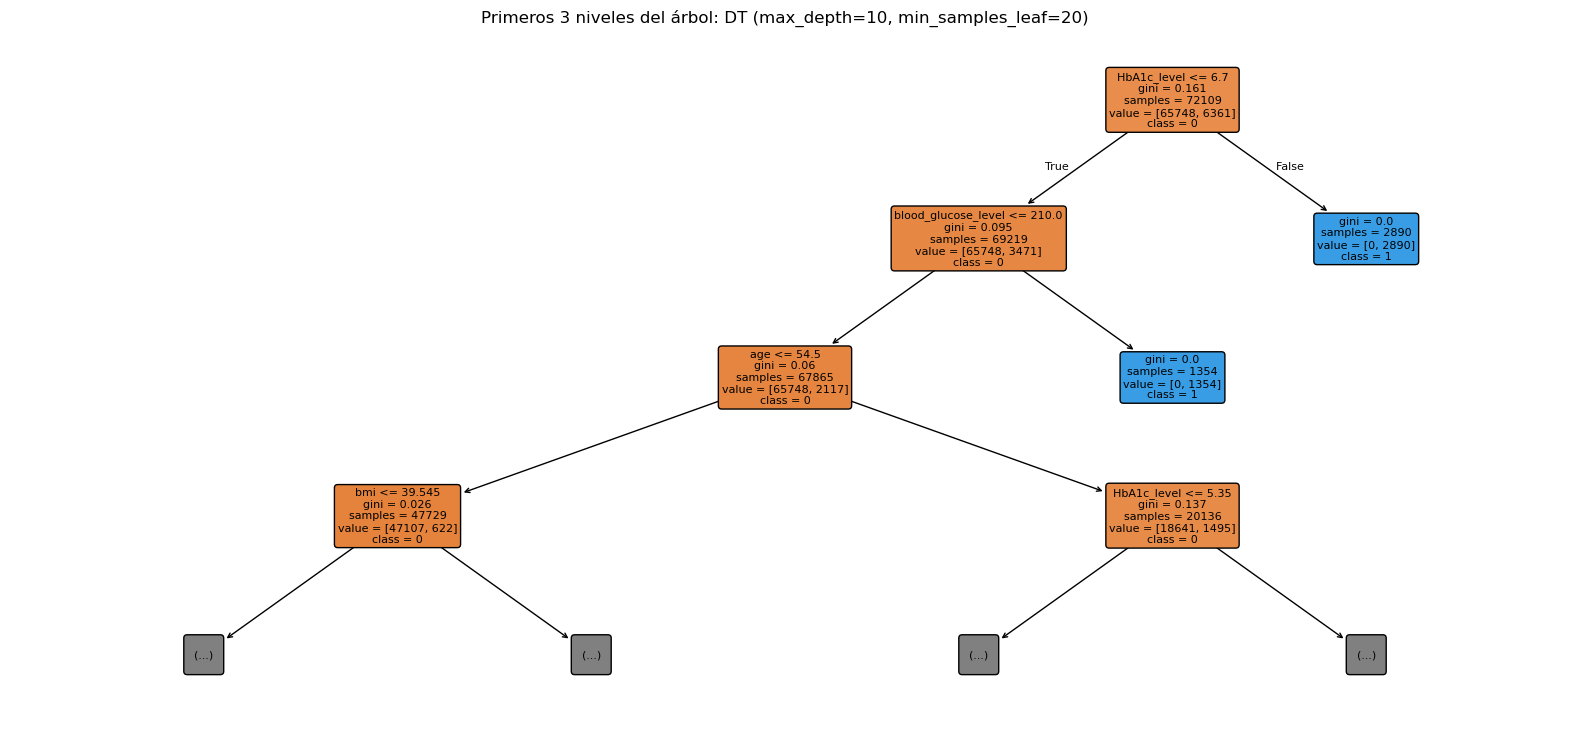

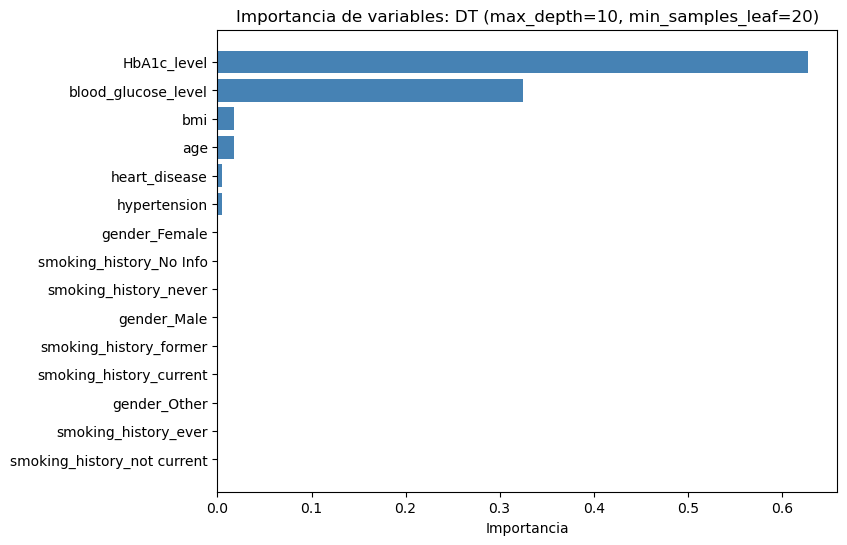

In [47]:
controller.ejecutar("Graficar árbol", nombre=mejores["DT"], profundidad=3)
guardar("dt_arbol.png")
plt.show()
controller.ejecutar("Importancia", nombre=mejores["DT"])
guardar("dt_importancia.png")
plt.show()

## Random Forest (RF)

In [48]:
controller.ejecutar("Comparar", algoritmo="bosque", configuraciones=[
    {},                                                  # estándar: 100 árboles, max_features=sqrt
    {"n_estimators": 300},
    {"n_estimators": 300, "max_depth": 12},
    {"n_estimators": 300, "min_samples_leaf": 5},
    {"n_estimators": 300, "max_features": None},         # bagging puro (todas las variables)
    {"n_estimators": 300, "max_depth": 12, "class_weight": "balanced_subsample"},
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
RF (estándar),0.9689,0.0311,0.9963,0.6860,0.9473,0.6860,0.7957,0.8895,0.9592
RF (n_estimators=300),0.9689,0.0311,0.9963,0.6855,0.9478,0.6855,0.7956,0.8894,0.9605
"RF (n_estimators=300, max_depth=12)",0.9713,0.0287,1.0000,0.6742,1.0000,0.6742,0.8054,0.8949,0.9704
"RF (n_estimators=300, min_samples_leaf=5)",0.9712,0.0288,0.9997,0.6761,0.9958,0.6761,0.8054,0.8949,0.9693
"RF (n_estimators=300, max_features=None)",0.9683,0.0317,0.9942,0.7011,0.9213,0.7011,0.7963,0.8895,0.9669
"RF (n_estimators=300, max_depth=12, class_weight=balanced_subsample)",0.9070,0.0930,0.9087,0.8897,0.4853,0.8897,0.6281,0.7875,0.9739


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
RF (estándar),0.9689,0.0311,0.9963,0.6860,0.9473,0.6860,0.7957,0.8895,0.9592
RF (n_estimators=300),0.9689,0.0311,0.9963,0.6855,0.9478,0.6855,0.7956,0.8894,0.9605
"RF (n_estimators=300, max_depth=12)",0.9713,0.0287,1.0000,0.6742,1.0000,0.6742,0.8054,0.8949,0.9704
"RF (n_estimators=300, min_samples_leaf=5)",0.9712,0.0288,0.9997,0.6761,0.9958,0.6761,0.8054,0.8949,0.9693
"RF (n_estimators=300, max_features=None)",0.9683,0.0317,0.9942,0.7011,0.9213,0.7011,0.7963,0.8895,0.9669
"RF (n_estimators=300, max_depth=12, class_weight=balanced_subsample)",0.9070,0.0930,0.9087,0.8897,0.4853,0.8897,0.6281,0.7875,0.9739


In [49]:
# Selección de atributos sobre el bosque estándar
controller.ejecutar("Random Forest", n_atributos=6)


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
RF (6 atributos),0.9676,0.0324,0.9937,0.6973,0.9152,0.6973,0.7915,0.8870,0.9561


Precisión Global     0.9676
Error Global         0.0324
Precisión clase 0    0.9937
Precisión clase 1    0.6973
Precision (VPP)      0.9152
Recall               0.6973
F1                   0.7915
F1 macro             0.8870
AUC                  0.9561
Name: RF (6 atributos), dtype: float64


[INFO]: Mejor modelo según F1 macro: RF (n_estimators=300, max_depth=12)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
2,"RF (n_estimators=300, max_depth=12)",RF,0.9713,0.0287,1.0000,0.6742,1.0000,0.6742,0.8054,0.8949,0.9704



--- Datos ---


,Pred 0,Pred 1
Real 0,21916,0
Real 1,691,1430


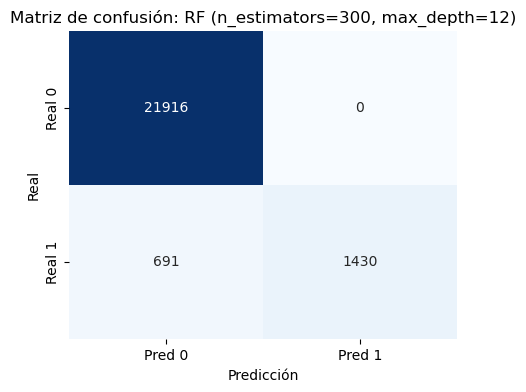


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.9698,0.7943,0.8890,0.9733
Fold 2,0.9702,0.7972,0.8905,0.9692
Fold 3,0.9705,0.7992,0.8917,0.9759
Fold 4,0.9705,0.8002,0.8921,0.9705
Fold 5,0.9719,0.8114,0.8981,0.9730
Promedio,0.9706,0.8005,0.8923,0.9724
Desv. estándar,0.0008,0.0065,0.0035,0.0026


In [50]:
mejores["RF"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="RF")
controller.ejecutar("Matriz confusión", nombre=mejores["RF"])
guardar("rf_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["RF"])

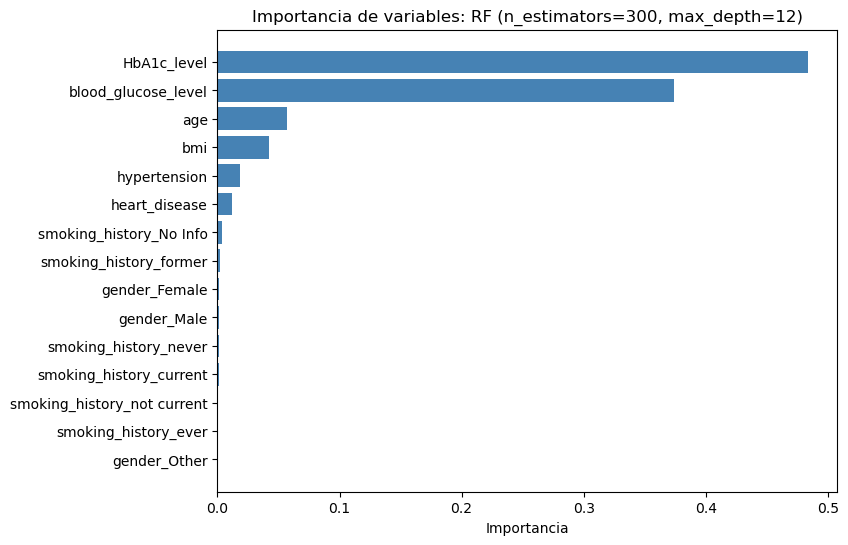

In [51]:
controller.ejecutar("Importancia", nombre=mejores["RF"])
guardar("rf_importancia.png")
plt.show()

## XGBoost

In [52]:
controller.ejecutar("Comparar", algoritmo="xgboost", configuraciones=[
    {},                                                  # estándar: 100 árboles, lr=0.3, profundidad 6
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 6, "subsample": 0.8, "colsample_bytree": 0.8},
    {"n_estimators": 500, "learning_rate": 0.1, "max_depth": 3},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4, "scale_pos_weight": 3},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4,
     "scale_pos_weight": round(ratio, 2)},               # peso completo según el desbalance
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
XGBoost (estándar),0.9699,0.0301,0.9970,0.6898,0.9575,0.6898,0.8019,0.8928,0.9759
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4)",0.9714,0.0286,0.9992,0.6836,0.9884,0.6836,0.8082,0.8964,0.9779
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8)",0.9706,0.0294,0.9981,0.6865,0.9726,0.6865,0.8049,0.8945,0.9775
"XGBoost (n_estimators=500, learning_rate=0.1, max_depth=3)",0.9711,0.0289,0.9983,0.6907,0.9747,0.6907,0.8085,0.8964,0.9777
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=3)",0.9615,0.0385,0.9802,0.7690,0.7894,0.7690,0.7791,0.8790,0.9779
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=10.34)",0.8972,0.1028,0.8948,0.9227,0.4591,0.9227,0.6131,0.7769,0.9779


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
XGBoost (estándar),0.9699,0.0301,0.9970,0.6898,0.9575,0.6898,0.8019,0.8928,0.9759
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4)",0.9714,0.0286,0.9992,0.6836,0.9884,0.6836,0.8082,0.8964,0.9779
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8)",0.9706,0.0294,0.9981,0.6865,0.9726,0.6865,0.8049,0.8945,0.9775
"XGBoost (n_estimators=500, learning_rate=0.1, max_depth=3)",0.9711,0.0289,0.9983,0.6907,0.9747,0.6907,0.8085,0.8964,0.9777
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=3)",0.9615,0.0385,0.9802,0.7690,0.7894,0.7690,0.7791,0.8790,0.9779
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=10.34)",0.8972,0.1028,0.8948,0.9227,0.4591,0.9227,0.6131,0.7769,0.9779



[INFO]: Mejor modelo según F1 macro: XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
1,"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4)",XGBoost,0.9714,0.0286,0.9992,0.6836,0.9884,0.6836,0.8082,0.8964,0.9779



--- Datos ---


,Pred 0,Pred 1
Real 0,21899,17
Real 1,671,1450


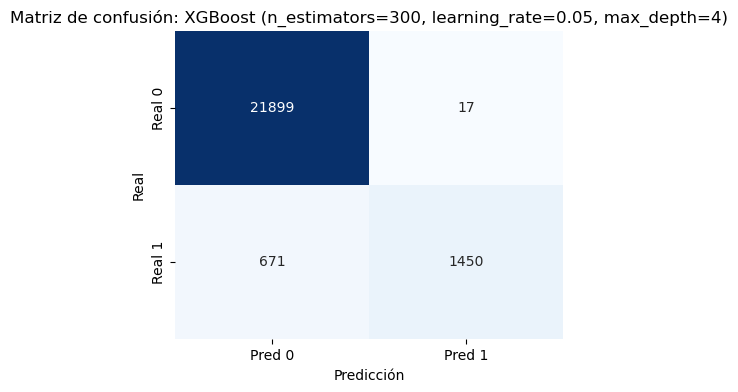


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.9705,0.8011,0.8926,0.9801
Fold 2,0.9705,0.8019,0.8930,0.9772
Fold 3,0.9707,0.8024,0.8933,0.9812
Fold 4,0.9703,0.8004,0.8922,0.9782
Fold 5,0.9722,0.8156,0.9003,0.9802
Promedio,0.9708,0.8043,0.8943,0.9794
Desv. estándar,0.0008,0.0064,0.0034,0.0016


In [53]:
mejores["XGBoost"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="XGBoost")
controller.ejecutar("Matriz confusión", nombre=mejores["XGBoost"])
guardar("xgboost_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["XGBoost"])

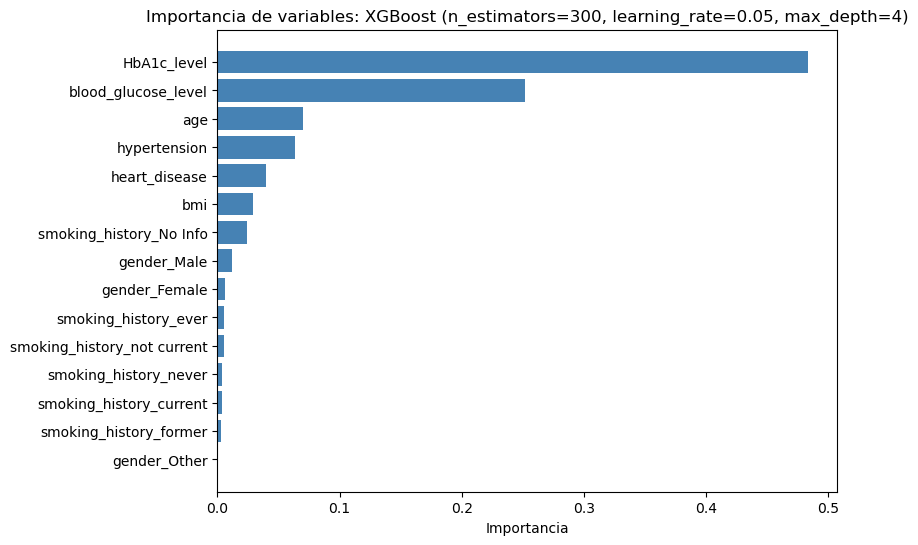

In [54]:
controller.ejecutar("Importancia", nombre=mejores["XGBoost"])
guardar("xgboost_importancia.png")
plt.show()

## AdaBoost

In [55]:
controller.ejecutar("Comparar", algoritmo="adaboost", configuraciones=[
    {},                                                  # estándar: 50 stumps, lr=1
    {"n_estimators": 200},
    {"n_estimators": 200, "learning_rate": 0.5, "profundidad_base": 2},
    {"n_estimators": 300, "learning_rate": 0.1, "profundidad_base": 3},
    {"n_estimators": 200, "learning_rate": 0.05, "profundidad_base": 4},
])


=== Índices de calidad ===


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
AdaBoost (estándar),0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9704
AdaBoost (n_estimators=200),0.9709,0.0291,0.9994,0.6766,0.9903,0.6766,0.8039,0.8941,0.9731
"AdaBoost (n_estimators=200, learning_rate=0.5, profundidad_base=2)",0.9711,0.0289,0.9999,0.6737,0.9979,0.6737,0.8044,0.8944,0.9740
"AdaBoost (n_estimators=300, learning_rate=0.1, profundidad_base=3)",0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9743
"AdaBoost (n_estimators=200, learning_rate=0.05, profundidad_base=4)",0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9744


,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
AdaBoost (estándar),0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9704
AdaBoost (n_estimators=200),0.9709,0.0291,0.9994,0.6766,0.9903,0.6766,0.8039,0.8941,0.9731
"AdaBoost (n_estimators=200, learning_rate=0.5, profundidad_base=2)",0.9711,0.0289,0.9999,0.6737,0.9979,0.6737,0.8044,0.8944,0.9740
"AdaBoost (n_estimators=300, learning_rate=0.1, profundidad_base=3)",0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9743
"AdaBoost (n_estimators=200, learning_rate=0.05, profundidad_base=4)",0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9744



[INFO]: Mejor modelo según F1 macro: AdaBoost (estándar)

=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
0,AdaBoost (estándar),AdaBoost,0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9704



--- Datos ---


,Pred 0,Pred 1
Real 0,21916,0
Real 1,694,1427


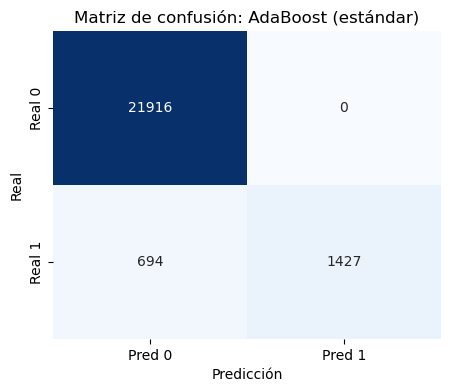


=== Índices de calidad ===


,Precisión Global,F1,F1 macro,AUC
Fold 1,0.9698,0.7939,0.8888,0.9735
Fold 2,0.9703,0.7972,0.8906,0.9709
Fold 3,0.9705,0.7994,0.8918,0.9758
Fold 4,0.9707,0.8011,0.8927,0.9687
Fold 5,0.9718,0.8101,0.8974,0.9739
Promedio,0.9706,0.8004,0.8923,0.9726
Desv. estándar,0.0008,0.0061,0.0032,0.0028


In [56]:
mejores["AdaBoost"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="AdaBoost")
controller.ejecutar("Matriz confusión", nombre=mejores["AdaBoost"])
guardar("adaboost_matriz.png")
plt.show()
controller.ejecutar("Validación cruzada", nombre=mejores["AdaBoost"])

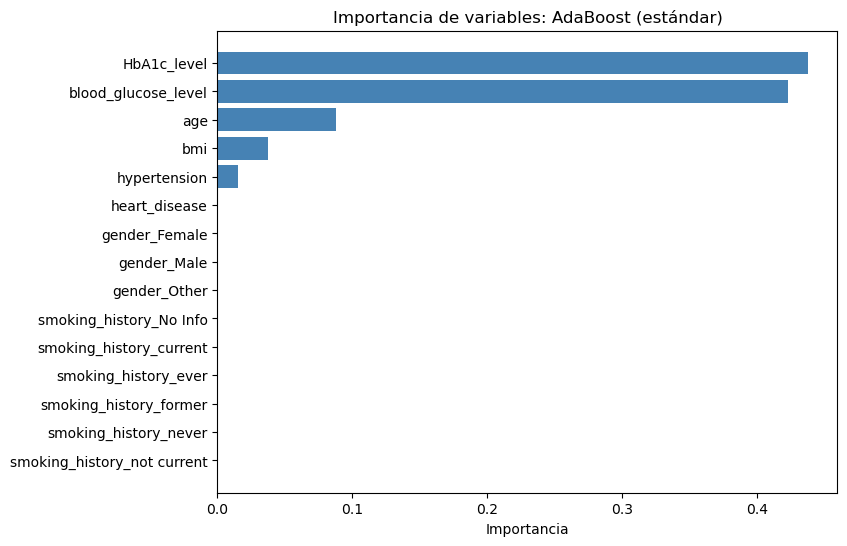

In [57]:
controller.ejecutar("Importancia", nombre=mejores["AdaBoost"])
guardar("adaboost_importancia.png")
plt.show()

## Comparación de los mejores modelos

In [58]:
controller.ejecutar("Resultados")


=== Índices de calidad ===


,Modelo,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
0,KNN (estándar),KNN,0.9589,0.0411,0.9925,0.6124,0.8873,0.6124,0.7247,0.8513,0.9022
1,KNN (n_neighbors=11),KNN,0.9599,0.0401,0.9963,0.5837,0.9393,0.5837,0.7200,0.8492,0.9325
2,KNN (n_neighbors=25),KNN,0.9596,0.0404,0.9984,0.5587,0.9713,0.5587,0.7094,0.8438,0.9512
3,"KNN (n_neighbors=11, weights=distance)",KNN,0.9599,0.0401,0.9948,0.5997,0.9171,0.5997,0.7252,0.8518,0.9306
4,"KNN (n_neighbors=11, p=1)",KNN,0.9599,0.0401,0.9973,0.5743,0.9531,0.5743,0.7167,0.8476,0.9326
5,"KNN (n_neighbors=11, sin escalar)",KNN,0.9533,0.0467,0.9974,0.4974,0.9487,0.4974,0.6526,0.8138,0.9146
6,"KNN (n_neighbors=11, 6 atributos)",KNN,0.9647,0.0353,0.9963,0.6384,0.9436,0.6384,0.7615,0.8712,0.9343
7,DT (estándar),DT,0.9477,0.0523,0.9682,0.7360,0.6916,0.7360,0.7131,0.8422,0.8524
8,DT (max_depth=5),DT,0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9492
9,DT (max_depth=10),DT,0.9709,0.0291,0.9988,0.6832,0.9817,0.6832,0.8057,0.8950,0.9712


In [59]:
tabla = model.resultados().set_index("Modelo").loc[list(mejores.values())]
view.mostrar_indices(tabla.sort_values(CRITERIO, ascending=False))


=== Índices de calidad ===


,Algoritmo,Precisión Global,Error Global,Precisión clase 0,Precisión clase 1,Precision (VPP),Recall,F1,F1 macro,AUC
Modelo,,,,,,,,,,
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=4)",XGBoost,0.9714,0.0286,0.9992,0.6836,0.9884,0.6836,0.8082,0.8964,0.9779
"DT (max_depth=10, min_samples_leaf=20)",DT,0.9713,0.0287,0.9991,0.6836,0.9864,0.6836,0.8076,0.8960,0.9718
"RF (n_estimators=300, max_depth=12)",RF,0.9713,0.0287,1.0000,0.6742,1.0000,0.6742,0.8054,0.8949,0.9704
AdaBoost (estándar),AdaBoost,0.9711,0.0289,1.0000,0.6728,1.0000,0.6728,0.8044,0.8944,0.9704
"KNN (n_neighbors=11, 6 atributos)",KNN,0.9647,0.0353,0.9963,0.6384,0.9436,0.6384,0.7615,0.8712,0.9343


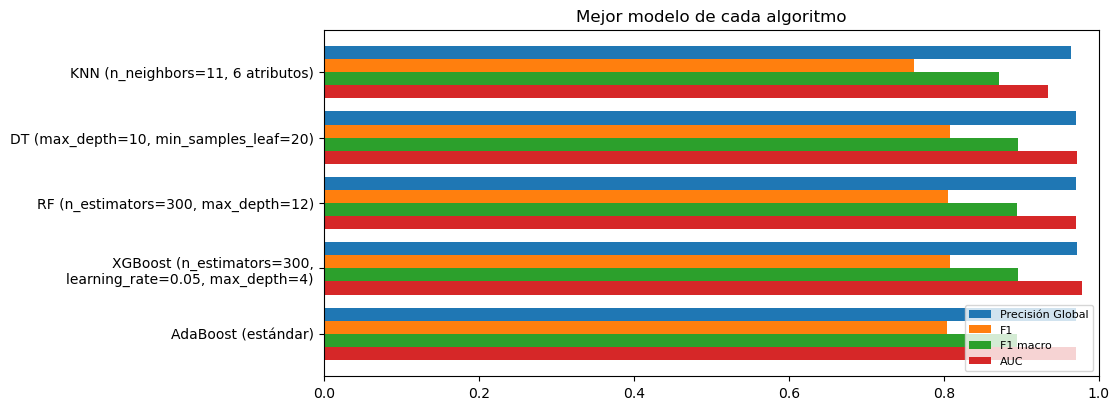

In [60]:
controller.ejecutar("Gráfico comparación", nombres=list(mejores.values()),
                    titulo="Mejor modelo de cada algoritmo")
guardar("comparacion_mejores.png")
plt.show()

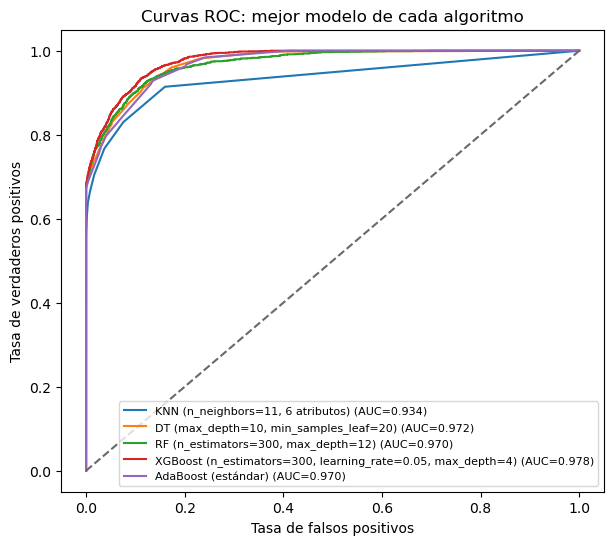

In [61]:
controller.ejecutar("ROC", nombres=list(mejores.values()), titulo="Curvas ROC: mejor modelo de cada algoritmo")
guardar("roc_mejores.png")
plt.show()

In [62]:
# Se guardan los índices de todos los experimentos
model.resultados().to_csv(f"{CARPETA}/resultados.csv", index=False)